# SupplyChain360: Business Analysis
Questions answered from the Gold layer of the warehouse (`gold` schema, built by dbt).

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd
from dotenv import find_dotenv, load_dotenv
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

load_dotenv(find_dotenv(usecwd=True))   # reads your passwords from .env

PORT = 5433   # the port your Postgres container is published on (see docker ps)

engine = create_engine(URL.create(
    "postgresql+psycopg",
    username=os.environ["POSTGRES_USER"],
    password=os.environ["POSTGRES_PASSWORD"],
    host="localhost",
    port=PORT,
    database=os.environ["POSTGRES_DB"],
))

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.figsize"] = (8, 4)


def q(sql):
    """Run a SQL query and return a DataFrame with numbers converted to floats."""
    df = pd.read_sql(sql, engine)
    for col in df.columns:
        if df[col].dtype == "object":
            try:
                df[col] = pd.to_numeric(df[col])
            except (ValueError, TypeError):
                pass
    return df


q("select current_database() as database, count(*) as sales_rows from gold.fact_sales")

Matplotlib is building the font cache; this may take a moment.


,database,sales_rows
0,supplychain_dw,12444


## Revenue trend

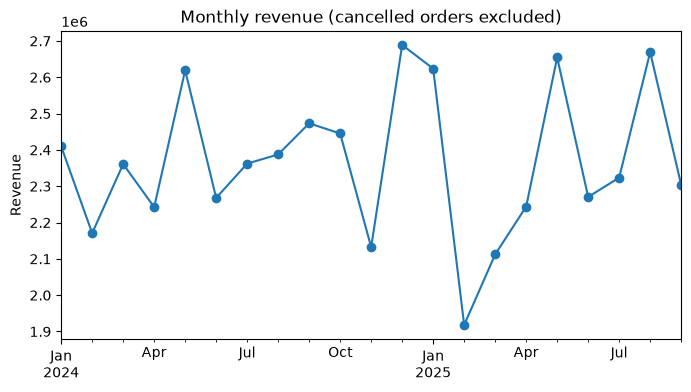

,month_start,orders,revenue
15,2025-04-01,196,"2,243,864.00"
16,2025-05-01,230,"2,654,448.00"
17,2025-06-01,212,"2,270,474.00"
18,2025-07-01,232,"2,323,589.00"
19,2025-08-01,240,"2,669,103.00"
20,2025-09-01,222,"2,303,888.00"


In [3]:
monthly = q("""
select make_date(d.year, d.month, 1)         as month_start,
       count(distinct f.order_id)            as orders,
       round(sum(f.net_revenue)::numeric, 0) as revenue
from gold.fact_sales f
join gold.dim_date d on d.date_key = f.order_date_key
where f.order_status <> 'Cancelled'
group by d.year, d.month
order by d.year, d.month
""")
monthly["month_start"] = pd.to_datetime(monthly["month_start"])

ax = monthly.plot(x="month_start", y="revenue", marker="o", legend=False,
                  title="Monthly revenue (cancelled orders excluded)")
ax.set_xlabel("")
ax.set_ylabel("Revenue")
plt.show()
monthly.tail(6)

## Q1. Which products and categories generate the most revenue?

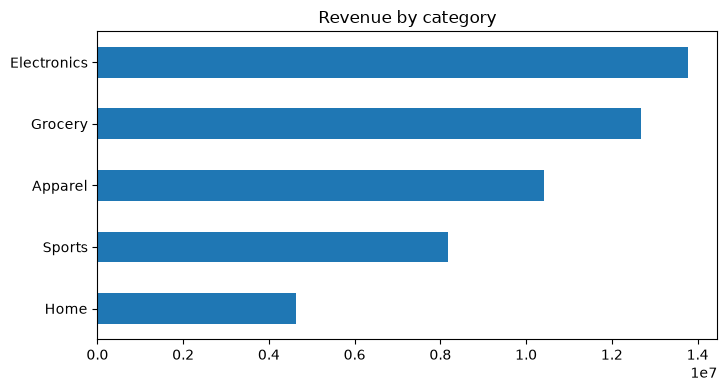

,category,revenue,profit,margin_pct
0,Electronics,"13,773,572.00","4,404,703.00",32.00
1,Grocery,"12,674,372.00","3,824,530.00",30.20
2,Apparel,"10,424,071.00","2,923,290.00",28.00
3,Sports,"8,180,423.00","2,794,763.00",34.20
4,Home,"4,627,457.00","1,539,515.00",33.30


,product_name,category,units,revenue
0,Product 76,Electronics,410.00,"1,206,483.00"
1,Product 43,Grocery,391.00,"1,117,348.00"
2,Product 40,Grocery,332.00,"1,079,921.00"
3,Product 74,Electronics,403.00,"1,000,266.00"
4,Product 11,Electronics,316.00,"989,894.00"
5,Product 9,Grocery,393.00,"979,933.00"
6,Product 78,Grocery,343.00,"976,960.00"
7,Product 7,Apparel,341.00,"909,055.00"
8,Product 22,Home,321.00,"896,365.00"
9,Product 93,Sports,319.00,"892,959.00"


In [4]:
categories = q("""
select p.category,
       round(sum(f.net_revenue)::numeric, 0) as revenue,
       round(sum(f.profit)::numeric, 0)      as profit,
       round((100.0 * sum(f.profit) / sum(f.net_revenue))::numeric, 1) as margin_pct
from gold.fact_sales f
join gold.dim_product p using (product_key)
where f.order_status <> 'Cancelled'
group by p.category
order by revenue desc
""")

top_products = q("""
select p.product_name, p.category,
       sum(f.quantity)                       as units,
       round(sum(f.net_revenue)::numeric, 0) as revenue
from gold.fact_sales f
join gold.dim_product p using (product_key)
where f.order_status <> 'Cancelled'
group by p.product_name, p.category
order by revenue desc
limit 10
""")

ax = categories.sort_values("revenue").plot.barh(x="category", y="revenue", legend=False,
                                                  title="Revenue by category")
ax.set_ylabel("")
plt.show()
display(categories)
display(top_products)

## Q2. Which customer segments spend the most?

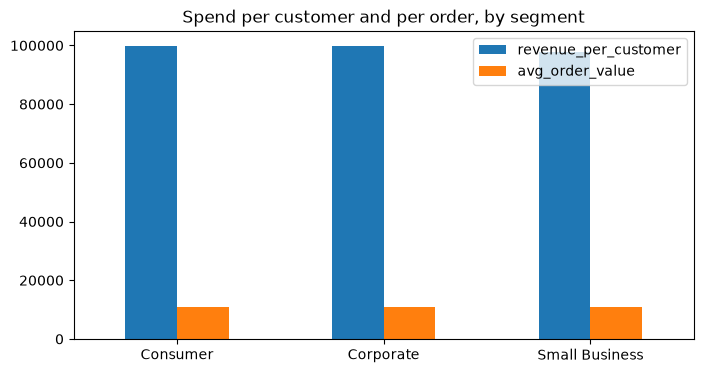

,customer_segment,orders,customers,revenue,avg_order_value,revenue_per_customer
0,Consumer,2881,316,"31,498,108.00","10,933.00","99,678.00"
1,Corporate,1015,110,"10,993,336.00","10,831.00","99,939.00"
2,Small Business,674,74,"7,237,447.00","10,738.00","97,803.00"


In [5]:
segments = q("""
select c.customer_segment,
       count(*)                                                           as orders,
       count(distinct o.customer_key)                                     as customers,
       round(sum(o.total_amount)::numeric, 0)                             as revenue,
       round((sum(o.total_amount) / count(*))::numeric, 0)                as avg_order_value,
       round((sum(o.total_amount) / count(distinct o.customer_key))::numeric, 0) as revenue_per_customer
from gold.fact_orders o
join gold.dim_customer c using (customer_key)
where o.order_status <> 'Cancelled'
group by c.customer_segment
order by revenue desc
""")

ax = segments.plot.bar(x="customer_segment", y=["revenue_per_customer", "avg_order_value"],
                       title="Spend per customer and per order, by segment")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.show()
segments

## Q3. Which suppliers have the longest lead times?

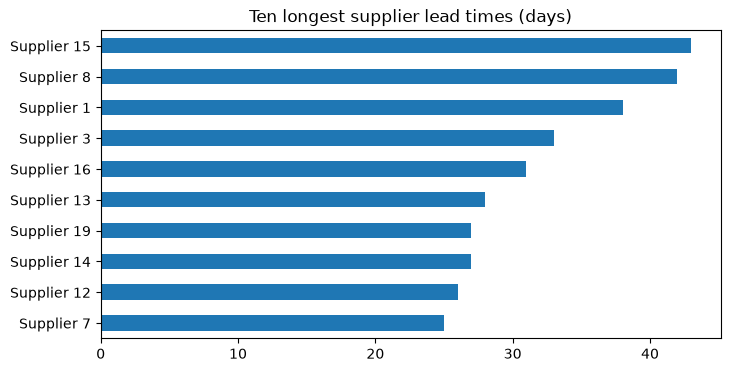

,supplier_name,supplier_location,supplier_category,lead_time,rating
0,Supplier 15,Berlin,Apparel,43,3.80
1,Supplier 8,Shenzhen,Home,42,2.80
2,Supplier 1,Berlin,Home,38,4.90
3,Supplier 3,Shenzhen,Grocery,33,4.50
4,Supplier 16,Delhi,Sports,31,3.90
5,Supplier 13,Dallas,Grocery,28,4.20
6,Supplier 14,Delhi,Electronics,27,3.30
7,Supplier 19,Mumbai,Electronics,27,4.40
8,Supplier 12,Shenzhen,Grocery,26,3.10
9,Supplier 7,Shenzhen,Apparel,25,3.60


In [6]:
suppliers = q("""
select supplier_name, supplier_location, supplier_category, lead_time, rating
from gold.dim_supplier
order by lead_time desc
limit 10
""")

ax = suppliers.sort_values("lead_time").plot.barh(x="supplier_name", y="lead_time", legend=False,
                                                   title="Ten longest supplier lead times (days)")
ax.set_ylabel("")
plt.show()
suppliers

## Q4. Which carriers have the highest delay rates?

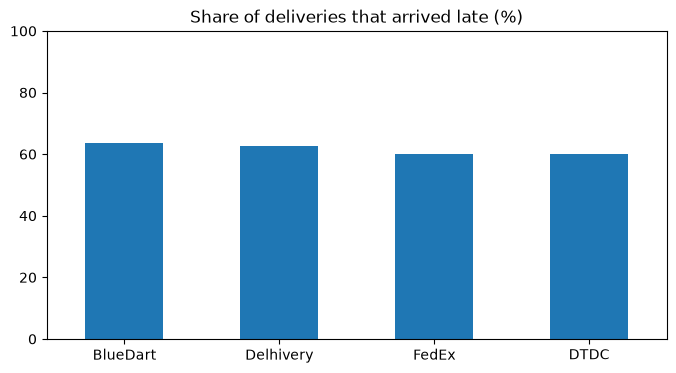

,carrier_name,delivered,delay_rate_pct,avg_delivery_days,avg_days_vs_expected,avg_shipping_cost
0,BlueDart,943,63.60,6.70,1.61,215.00
1,Delhivery,928,62.80,6.50,1.56,221.00
2,FedEx,931,59.90,6.30,1.36,219.00
3,DTDC,918,59.90,6.40,1.42,221.00


In [7]:
carriers = q("""
select c.carrier_name,
       count(*)                                                        as delivered,
       round(100.0 * avg(case when s.is_delayed then 1 else 0 end), 1) as delay_rate_pct,
       round(avg(s.delivery_days), 1)                                  as avg_delivery_days,
       round(avg(s.delivery_days - s.expected_days), 2)                as avg_days_vs_expected,
       round(avg(s.shipping_cost)::numeric, 0)                         as avg_shipping_cost
from gold.fact_shipments s
join gold.dim_carrier c using (carrier_key)
where s.is_delayed is not null
group by c.carrier_name
order by delay_rate_pct desc
""")

ax = carriers.plot.bar(x="carrier_name", y="delay_rate_pct", legend=False,
                       title="Share of deliveries that arrived late (%)")
ax.set_xlabel("")
ax.set_ylim(0, 100)
plt.xticks(rotation=0)
plt.show()
carriers

## Q5. Which warehouses are over-utilized?

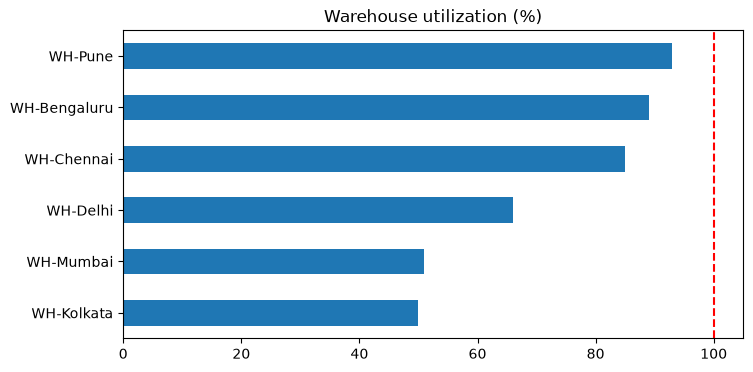

,warehouse_name,city,capacity,utilization_pct,is_over_utilized
0,WH-Pune,Pune,19064,93.00,False
1,WH-Bengaluru,Bengaluru,16362,89.00,False
2,WH-Chennai,Chennai,18331,85.00,False
3,WH-Delhi,Delhi,18832,66.00,False
4,WH-Mumbai,Mumbai,7736,51.00,False
5,WH-Kolkata,Kolkata,6913,50.00,False


In [8]:
warehouses = q("""
select warehouse_name, city, capacity,
       round((100 * current_utilization)::numeric, 0) as utilization_pct,
       is_over_utilized
from gold.dim_warehouse
order by current_utilization desc
""")

ax = warehouses.sort_values("utilization_pct").plot.barh(
    x="warehouse_name", y="utilization_pct", legend=False, title="Warehouse utilization (%)")
ax.axvline(100, color="red", linestyle="--")   # anything beyond this line is over capacity
ax.set_ylabel("")
plt.show()
warehouses

## Q6. Which products are frequently below reorder level?

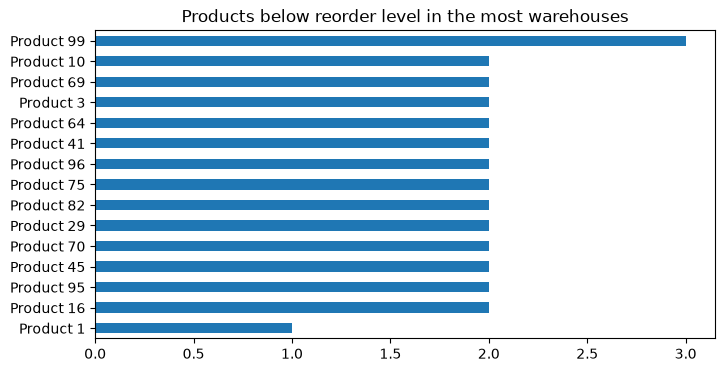

,product_name,category,warehouses_stocked,warehouses_low,pct_low,stockouts
0,Product 99,Grocery,5,3,60.00,0
1,Product 16,Electronics,3,2,67.00,0
2,Product 45,Apparel,3,2,67.00,0
3,Product 95,Sports,4,2,50.00,0
4,Product 75,Grocery,4,2,50.00,0
5,Product 29,Grocery,4,2,50.00,0
6,Product 70,Apparel,4,2,50.00,0
7,Product 82,Apparel,4,2,50.00,0
8,Product 41,Apparel,4,2,50.00,0
9,Product 3,Grocery,4,2,50.00,0


In [9]:
low_stock = q("""
select p.product_name, p.category,
       count(*)                                                       as warehouses_stocked,
       sum(case when i.is_low_stock then 1 else 0 end)                as warehouses_low,
       round(100.0 * avg(case when i.is_low_stock then 1 else 0 end), 0) as pct_low,
       sum(case when i.stock_quantity = 0 then 1 else 0 end)          as stockouts
from gold.fact_inventory i
join gold.dim_product p using (product_key)
group by p.product_name, p.category
having sum(case when i.is_low_stock then 1 else 0 end) > 0
order by warehouses_low desc, pct_low desc
limit 15
""")

ax = low_stock.sort_values("warehouses_low").plot.barh(
    x="product_name", y="warehouses_low", legend=False,
    title="Products below reorder level in the most warehouses")
ax.set_ylabel("")
plt.show()
low_stock

Findings :

Revenue figures exclude cancelled orders. Total revenue is about 49.7M.

PProducts and categories: Electronics is the top category in sales at 13.8M (approximately 28% of the total) and the largest profit at 4.4M. Second is Grocery with 12.7M. Home is the smallest category at 4.6M (around 9%) but has one of the best margins (33.3%). Sports has the best margin (34.2%) and Apparel the weakest (28.0%) of the sectors although it is third in revenue. Top 10 products account for approximately 10M or about a fifth of total revenues, spread across all five categories with no one product dominating.

Customer segments : Consumers account for ~63% of revenue (31.5M) but only because they are the largest group at 316 of 500 customers. The average order value is almost identical (10.7K to 10.9K) and per customer the three segments are almost identical (around 98K to 100K). Segment is not a strong predictor of spend in this dataset.

Suppliers: Supplier 15 (Berlin) has the longest lead time at 43 days, followed by Supplier 8 (Shenzhen) at 42 days. Four of the slowest suppliers are in Shenzhen. Lead time is not quality: Supplier 1 takes 38 days but scores 4.9. The first supplier you should check is Supplier 8 because it is the slowest and worst rated of the ten, at 2.8. Also under the alert threshold of 3.5 are suppliers 14 and 12 (ratings 3.3 and 3.1).

Carriers: On average, all four carriers are delivering late on approximately 60% to 64% of shipments, 1.4 to 1.6 days beyond the expected delivery date. BlueDart is the worst (63.6% late) and FedEx and DTDC are the best (59.9%). The difference is small (3.7 points), and the average shipping cost is about the same across carriers (215 to 221) so switching carriers wouldn’t necessarily save time or money.

Warehouses: I notice that no Warehouse reaches over capacity. Warehouse in Pune is ninety-three percent Warehouse in Bengaluru is eighty-nine percent full and Warehouse in Chennai is eighty-five percent full; these three Warehouses are the largest sites. Warehouse in Mumbai is fifty-one percent Warehouse, in Kolkata is fifty percent full meaning each of those Warehouses is about half empty. This uneven use shows that Warehouse capacity is not balanced.

Reorder levels: No product in the 15 has hit zero stock but several products are below their reorder level in half or more of the warehouses that carry them. Product 99 (Grocery) is low in 3 of 5 warehouses and products 16 and 45 are low, in 2 of 3 warehouses. Apparel (6 products) and Grocery (5 products) dominate the list. Product 1 shows 100% low. Product 1 is stocked in only one warehouse so that figure is a small sample.

Suggested actions
1. Review Supplier 8: long lead time and the lowest rating.
2. Watch capacity at Pune and Bengaluru, and consider moving stock to Mumbai or Kolkata.
3. Restock Products 99, 16 and 45 first.
4. Look at why Apparel's margin is the lowest of the five categories.

### Data note
This dataset is simulated. Groups differ only slightly (segments, carriers), because the generator assigned values randomly. With real company data, these same queries would be far more revealing.